# Сравнение: FEM → coarse Galerkin → GMsFEM → neural operators

Фиксируем одну и ту же задачу для каждого held-out примера: DG0 A,n, k, направление и исходную тонкую FEM-сетку. Метрика всех методов:
\[
\|u_{method}^s-u_{FEM}^s\|_M/\|u_{FEM}^s\|_M.
\]
Fine FEM — reference, а не точное аналитическое решение. Его почти нулевая ошибка к собственным меткам не означает превосходство по точности. Coarse baseline — Q1 traces, интерполированные в fine P1 и решённые Galerkin-проекцией; это не самостоятельная coarse P1-сетка. GMsFEM использует существующие snapshots Type 1/2 и спектральные пространства `gmsfem.offline`.

Основная paired-таблица содержит по одному направлению **трёх** test-сред для всех методов. Полная neural-таблица по всем 32 test-примерам показывается отдельно. Повторяющиеся направления одной среды статистически зависимы. Числа параметров сетей и FEM DOF не являются одной и той же величиной.


In [1]:
from pathlib import Path
import sys
ROOT = next(p for p in (Path.cwd(), *Path.cwd().parents) if (p / 'neural_operator').is_dir())
if str(ROOT) not in sys.path:
    sys.path.insert(0, str(ROOT))
BASE = ROOT / 'neural_operator'
DATA_DIR = BASE / 'data' / 'low_frequency'
RUNS = BASE / 'runs' / 'low_frequency'
import json
import numpy as np
import matplotlib.pyplot as plt
from neural_operator.data import load_dataset
from neural_operator.plotting import display_table, plot_prediction, plot_history


In [2]:
from neural_operator.experiments import compare_methods
from neural_operator.diagnostics import write_csv, transfer_diagnostics
dataset = load_dataset(DATA_DIR)
OUT = BASE / 'runs' / 'comparison'
run_dirs = {method: RUNS / method for method in ['svd', 'chebyshev', 'fno']}
paired, summaries, neural_full = compare_methods(dataset, run_dirs, OUT,
    n_media=3, n_coarse=4, modes=(1, 2, 4), basis_types=(1, 2))
display_table(summaries)


Info    : Reading '/workspace/multiscale-fem-scattering/neural_operator/data/low_frequency/etal.msh'...
Info    : 175 entities
Info    : 3221 nodes
Info    : 6440 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/neural_operator/data/low_frequency/etal.msh'


Info    : Reading '/workspace/multiscale-fem-scattering/neural_operator/data/low_frequency/etal.msh'...
Info    : 175 entities
Info    : 3221 nodes
Info    : 6440 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/neural_operator/data/low_frequency/etal.msh'


Info    : Reading '/workspace/multiscale-fem-scattering/neural_operator/data/low_frequency/etal.msh'...
Info    : 175 entities
Info    : 3221 nodes
Info    : 6440 elements
Info    : Done reading '/workspace/multiscale-fem-scattering/neural_operator/data/low_frequency/etal.msh'


method,mean,median,p95,max,paired_samples,online_seconds_mean,offline_seconds_mean,assembly_seconds_mean,training_seconds
Fine FEM reference,0,0,0,0,3,0.00666,0,0.11126,0
Coarse Q1 traces in fine P1,0.35278,0.3875,0.40662,0.40875,3,0.00060406,0.00034104,0.11126,0
"GMsFEM Type 1, M=1",0.34816,0.38461,0.40494,0.4072,3,0.00059818,0.11387,0.11126,0
"GMsFEM Type 1, M=2",0.29697,0.32329,0.36512,0.36977,3,0.0010468,0.11387,0.11126,0
"GMsFEM Type 1, M=4",0.094564,0.099826,0.1034,0.1038,3,0.0025692,0.11387,0.11126,0
"GMsFEM Type 2, M=1",0.5845,0.49271,0.94038,0.99012,3,0.00059456,0.1142,0.11126,0
"GMsFEM Type 2, M=2",0.53863,0.43945,0.91628,0.96926,3,0.0010589,0.1142,0.11126,0
"GMsFEM Type 2, M=4",0.085271,0.082616,0.097918,0.099618,3,0.0025468,0.1142,0.11126,0
SVD-SNO,0.61843,0.61844,0.62414,0.62478,3,0.00054715,0.26898,0,4.9879
Chebyshev-SNO,0.67488,0.64315,0.80503,0.82301,3,0.00090572,0.085635,0,17.744


## Полный test только для нейрооператоров

Времена warm inference включают кодирование входа, вызов модели и восстановление FEM-поля. Для GMsFEM отдельно сохранены assembly, построение базиса и полный online solve с реконструкцией. Базис строится один раз до максимального M серии; соответствующая стоимость указывается во всех строках серии. При новой среде/k эта стоимость возникает снова. Training и preprocessing сетей показаны отдельно и не скрыты в оценке ускорения.


In [3]:
display_table(neural_full)
transfer_rows = transfer_diagnostics(dataset, dataset.split_indices()[2], resolution=32)
write_csv(OUT / 'transfer_test.csv', transfer_rows)
display_table(transfer_rows)


method,mean,median,p95,max,samples,media,batch_seconds_per_sample,single_seconds_median,preprocessing_seconds,training_seconds,parameters
SVD-SNO,0.68581,0.63056,1.0659,1.184,32,8,5.7676e-05,0.00045425,0.26898,4.9879,68666
Chebyshev-SNO,0.70624,0.72681,0.82703,0.85228,32,8,0.00015298,0.00085358,0.085635,17.744,2426
FNO,0.38839,0.37202,0.59649,0.67381,32,8,0.00071864,0.0017775,0.093752,78.461,445010


grid,resolution,field,mean_fem_l2,p95_fem_l2
uniform,32,A,0.011983,0.015436
uniform,32,n,0.052923,0.077045
uniform,32,u_scat,0.024316,0.035963
chebyshev,32,A,0.01832,0.023095
chebyshev,32,n,0.07974,0.11387
chebyshev,32,u_scat,0.036793,0.049841


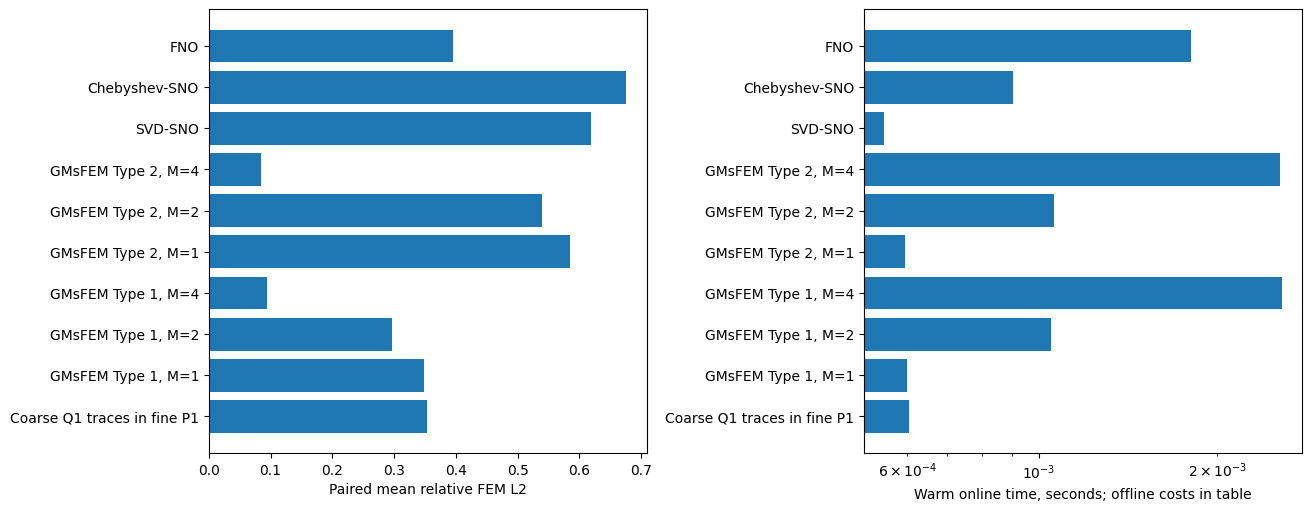

In [4]:
visible = [row for row in summaries if row['method'] != 'Fine FEM reference']
fig, axes = plt.subplots(1, 2, figsize=(13, 5), constrained_layout=True)
labels = [r['method'] for r in visible]
y = np.arange(len(labels))
axes[0].barh(y, [r['mean'] for r in visible]); axes[0].set_yticks(y, labels)
axes[0].set(xlabel='Paired mean relative FEM L2')
axes[1].barh(y, [r['online_seconds_mean'] for r in visible]); axes[1].set_yticks(y, labels)
axes[1].set(xscale='log', xlabel='Warm online time, seconds; offline costs in table')
fig.savefig(OUT / 'paired_comparison.png', dpi=160)
plt.show()


Небольшой seed-фиксированный эксперимент не определяет универсальный рейтинг методов. На локальные GMsFEM пространства влияют число мод и локальные резонансы; на нейрооператоры — число сред, пространственный перенос и tuning budget. Статьи и точные отличия реализации: [docs/references.md](docs/references.md).
